# EDA

In [1]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_ACCESS_TOKEN").strip()

In [2]:
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026

100% 9.88G/9.88G [06:48<00:00, 26.0MB/s]



In [3]:
!unzip ./multiple-object-video-detection-hw-2-ucu-ai-2026.zip -d ./object-detection-data

Streaming output truncated to the last 5000 lines.
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000229.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000230.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000231.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000232.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000233.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000234.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000235.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000236.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000237.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000238.jpg  
  inflating: ./object-detection-data/val/images/uav0000117_02622_v/0000239.jpg  
  inflating: ./object-detection-data/val/images/uav0000117

In [31]:
import json
from pathlib import Path

In [32]:
import scripts.eda as eda

In [33]:
DATA_ROOT = Path("./object-detection-data")

In [34]:
data_root, out_root, report_dir = Path(DATA_ROOT), Path(eda.OUT_ROOT), Path(eda.REPORT_DIR)
report_dir.mkdir(parents=True, exist_ok=True)
eda.set_global_seed(eda.SEED)

### General information

In [35]:
images, objects, ignores, frames, clips, counts = eda.load_tables(data_root)
print(f"{len(frames)} frames, {len(clips)} clips, {len(objects)} objects, {len(ignores)} ignored regions")
print("Image sizes")
print(eda.compare_resolutions(images, data_root / "test_images.csv").to_string())

27047 frames, 63 clips, 1219648 objects, 542704 ignored regions
Image sizes
              train_val_frames  test_frames
width height                               
680   382                    0          321
960   540                    0          279
1344  756                 6472          441
1360  764                    0         1474
      765                  962            0
1904  1071               13354            0
      1072                   0          305
1920  1080                 721          991
2688  1512                3738            0
2720  1530                 822            0
3840  2160                 978            0


We can see that images have very differnt resolutions, which will complicate choosing optimal one.

#### Statistics across clips

In [22]:
clips.to_csv(report_dir / "per_clip_stats.csv")
print(clips.drop(columns="split").describe().T[["min", "25%", "50%", "75%", "max"]].round(2).to_string())

Variation across clips
                      min      25%      50%      75%      max
n_frames            58.00   227.50   363.00   547.50  1424.00
width             1344.00  1904.00  1904.00  2304.00  3840.00
height             756.00  1071.00  1071.00  1296.00  2160.00
objs_per_frame       5.15    29.11    44.19    57.25   142.96
ignore_per_frame     0.00     7.98    13.14    31.11   131.05
median_size_px      24.49    41.23    48.08    57.50    86.82
small_frac           0.00     0.09     0.18     0.28     0.73
occluded_frac        0.03     0.35     0.49     0.58     0.88
Object size by class [px]
              count    p5  median    p95  <16px %  <32px %  >96px %
person     379013.0  17.0    36.7   72.7      3.8     37.5      0.7
bicycle     46277.0  21.2    43.9   89.0      2.8     21.6      2.8
car        537122.0  23.5    57.5  150.6      0.7     15.9     19.2
van         53782.0  24.9    51.3  165.5      0.2     19.4     16.7
truck       31857.0  28.7    73.9  215.2      0.0    

Average number of object per frame is 44 and average occlusion is 0.49, which shows that dataset features heavy overlapping and dense crods. This needs to be taken into accout as it will affect model's performance.

Also we see high average of ignore regions, those will need to be masked to not affect the model.

From second table we see that dataset is pretty imbalanced: people and cars dominate it, while buses are the rares category. This can cause model to overfit and ignore minority classes.

#### Object size by class

In [27]:
size_table = eda.size_summary_by_class(objects)
size_table.to_csv(report_dir / "size_by_class.csv")
print(size_table.to_string())

              count    p5  median    p95  <16px %  <32px %  >96px %
person     379013.0  17.0    36.7   72.7      3.8     37.5      0.7
bicycle     46277.0  21.2    43.9   89.0      2.8     21.6      2.8
car        537122.0  23.5    57.5  150.6      0.7     15.9     19.2
van         53782.0  24.9    51.3  165.5      0.2     19.4     16.7
truck       31857.0  28.7    73.9  215.2      0.0      9.1     33.4
tricycle    46836.0  21.4    54.5  130.0      0.6     20.7     14.0
bus          9917.0  32.4   111.7  286.0      0.0      4.0     56.6
motor      114844.0  16.9    39.8   79.5      4.1     31.4      1.7
ALL       1219648.0  19.9    46.4  130.3      2.0     24.4     11.6


Almost 1/4 of all objects are smaller that 32 px, this number is even higher for people and motorcycle which will be a challenge for the models because successive downsampling layers in deep neural networks strip away critical spatial and textural information, which could lead to missed anchor matches, degraded feature representations, and high background confusion across all model architectures.

#### Plots

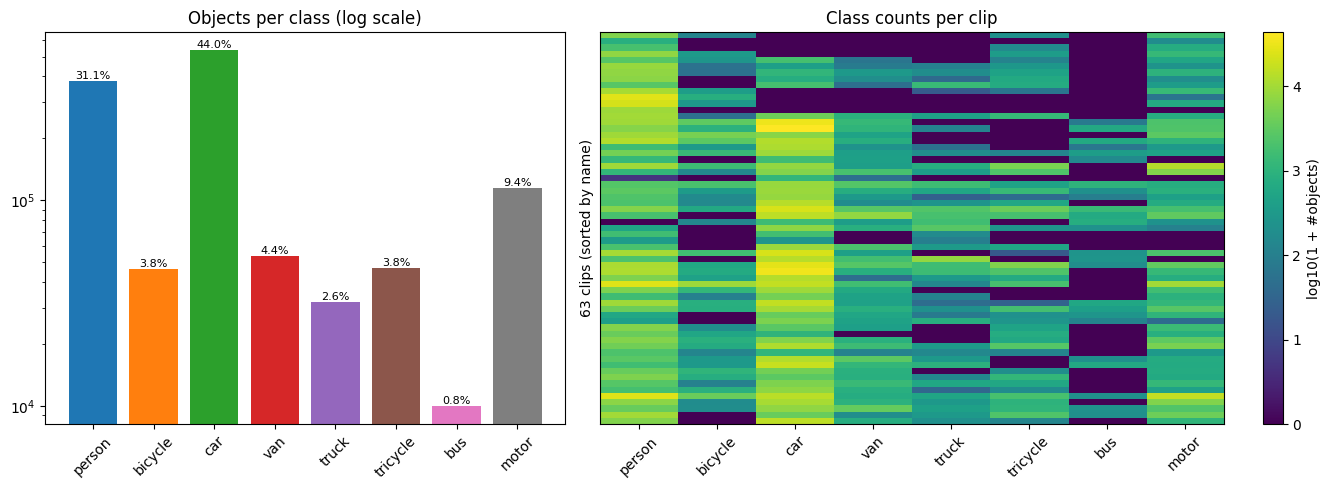

In [23]:
eda.finish_figure(eda.plot_class_distribution(counts), "class_distribution", report_dir)

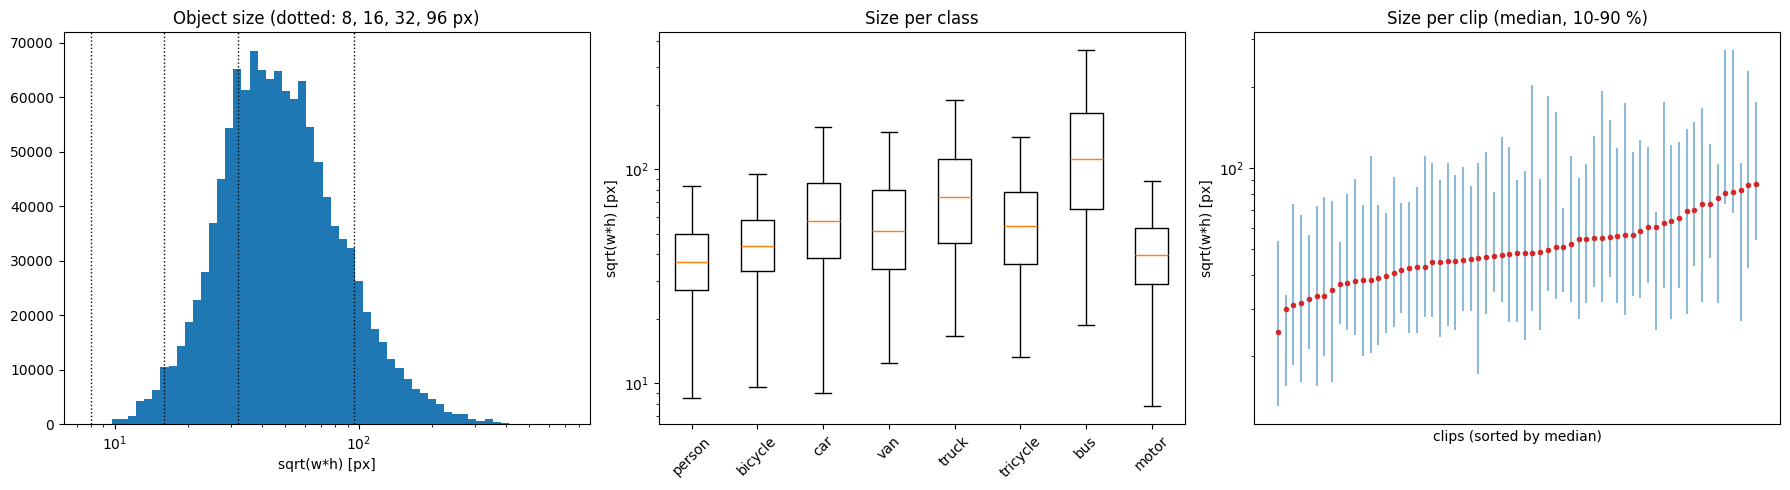

In [24]:
eda.finish_figure(eda.plot_size_distribution(objects), "size_distribution", report_dir)

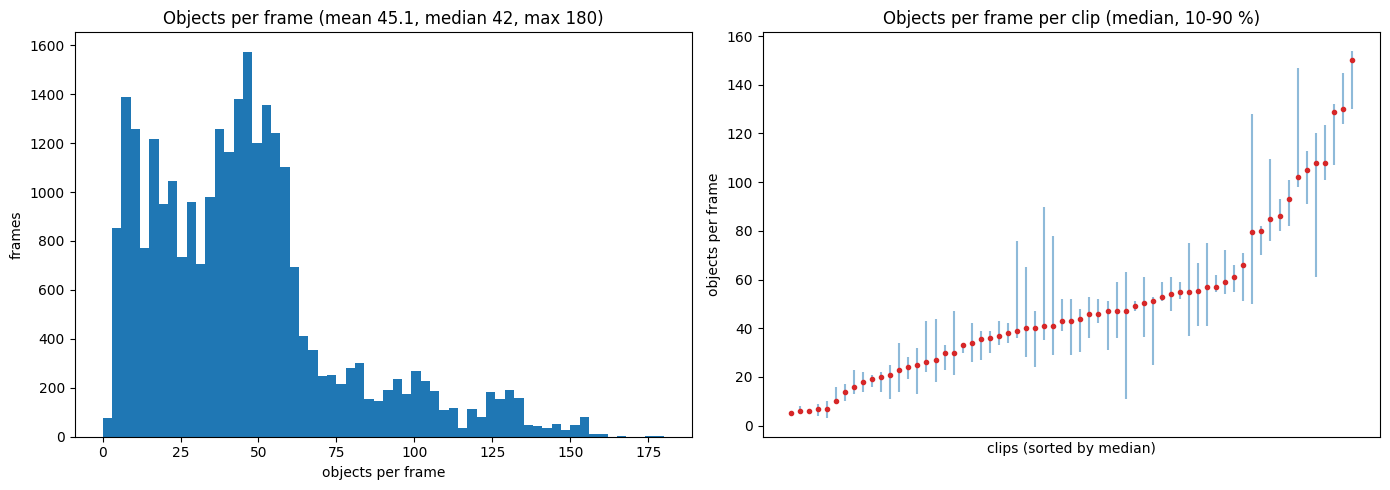

In [25]:
eda.finish_figure(eda.plot_objects_per_frame(frames), "objects_per_frame", report_dir)

#### Optimizations of size, anchor and other

In [28]:
decisions = eda.report_decisions(objects)
step = eda.STEP or decisions["step"]

eda.verify_conversion(objects, frames, data_root).to_csv(report_dir / "conversion_mismatches.csv", index=False)

yaml_path = eda.split_and_build(frames, objects, ignores, clips, counts, step, out_root)


Object size after letterbox resize (tiny < 8 px, small < 16 px)
 imgsz  median_px  frac_tiny  frac_small
   640     15.286      0.097       0.536
   960     22.929      0.018       0.235
  1280     30.572      0.006       0.097
  1536     36.686      0.002       0.048
Optimal imgsz: 640
K-means anchors at imgsz=640 (w, h in input px; mean best IoU 0.73)
[[ 7.4  7.1]
 [ 5.7 11.8]
 [13.8 10.4]
 [ 9.1 16.5]
 [21.6 14.8]
 [13.8 23.3]
 [37.6 19.8]
 [23.9 31.9]
 [56.1 40. ]]
Frame similarity vs gap (same track_id)
 gap  persistence  mean_iou  median_iou
   1        0.993     0.846       0.895
   2        0.986     0.745       0.806
   3        0.979     0.668       0.727
   5        0.966     0.557       0.591
   8        0.946     0.450       0.432
  10        0.932     0.401       0.348
  15        0.901     0.321       0.194
  30        0.811     0.219       0.000
Best subsampling step: 3
Class imbalance: most/least frequent class ratio: 54x (car vs bus)
Conversion check: 0 / 27047 frames

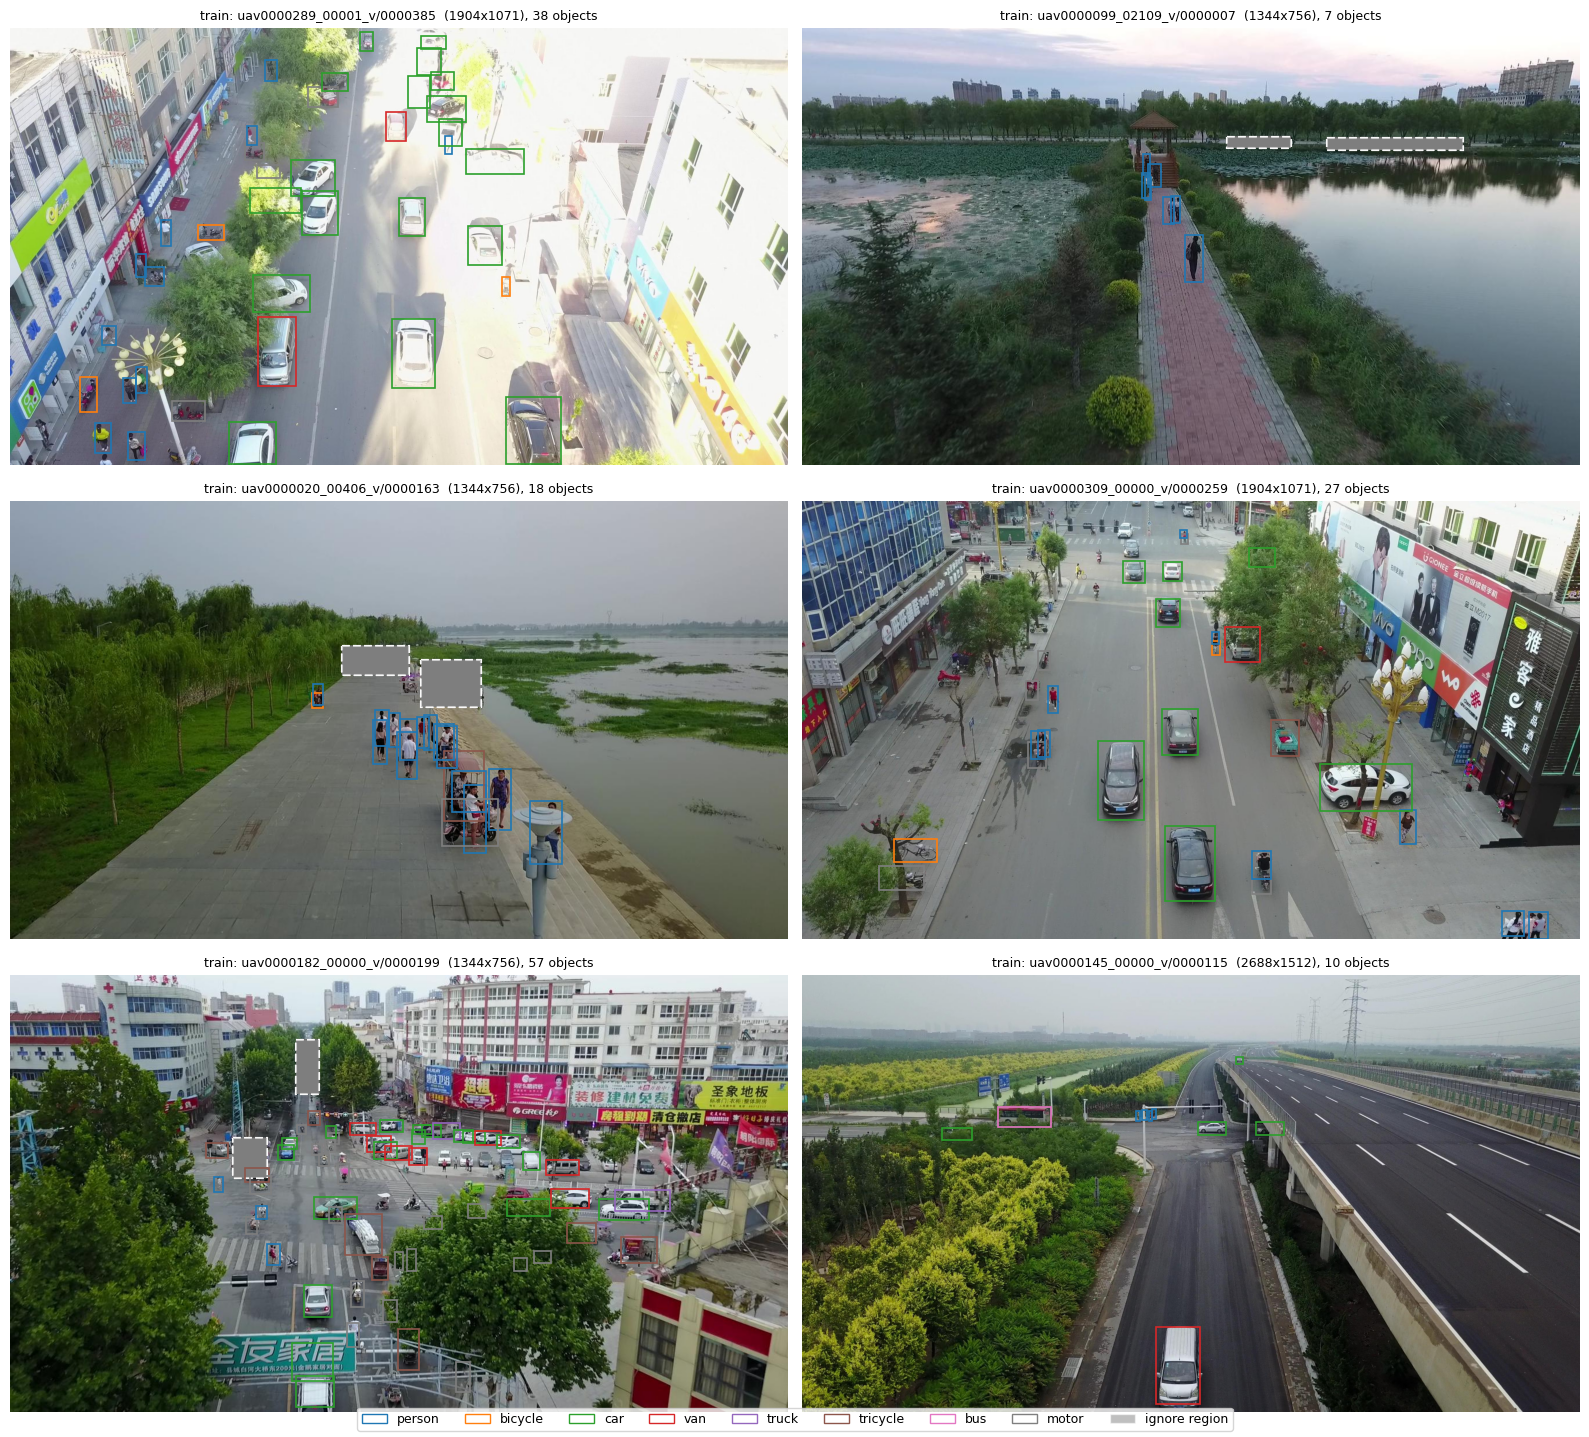

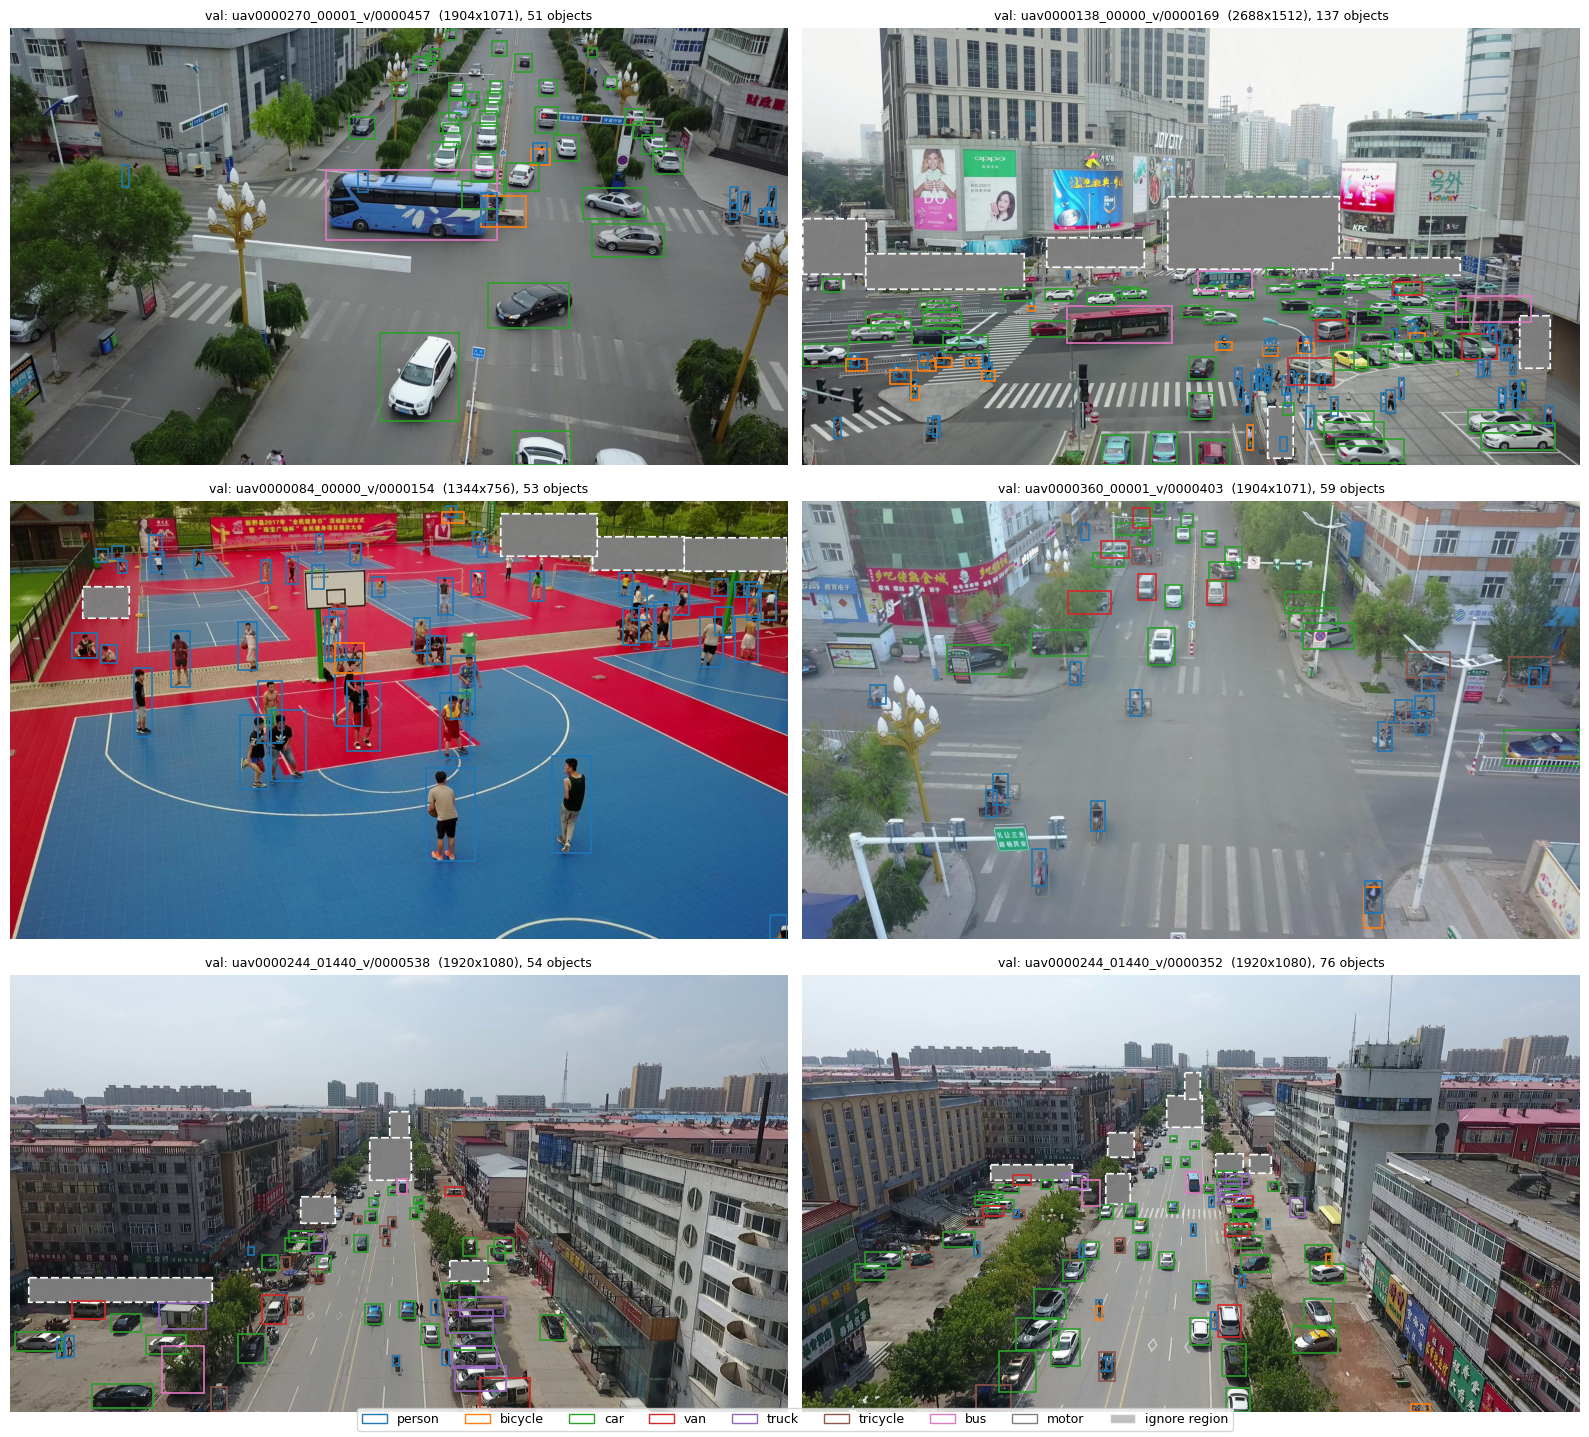

In [29]:
for split in ("train", "val"):
    eda.finish_figure(eda.visualize_samples(out_root, split), f"gt_samples_{split}", report_dir)

In [36]:
cfg = eda.build_train_config(yaml_path, decisions["imgsz"], decisions["small_frac"])
(report_dir / "train_config.json").write_text(json.dumps(cfg, indent=2))
print("\ntrain config:", json.dumps(cfg, indent=2))


train config: {
  "data": "/content/prepared/data.yaml",
  "imgsz": 640,
  "rect": false,
  "seed": 42,
  "deterministic": true,
  "mosaic": 1.0,
  "close_mosaic": 10,
  "mixup": 0.0,
  "scale": 0.3,
  "translate": 0.1,
  "degrees": 0.0,
  "shear": 0.0,
  "perspective": 0.0,
  "fliplr": 0.5,
  "flipud": 0.0,
  "hsv_h": 0.015,
  "hsv_s": 0.7,
  "hsv_v": 0.4
}
